<a href="https://colab.research.google.com/github/dhyun16/ESAA/blob/main/%EB%AF%B8%EB%8B%88%ED%94%84%EB%A1%9C%EC%A0%9D%ED%8A%B82_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd

train = pd.read_csv('train.csv', index_col='index')
train.head()

,quality,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,type
index,,,,,,,,,,,,,
0,5,5.6,0.695,0.06,6.8,0.042,9.0,84.0,0.99432,3.44,0.44,10.2,white
1,5,8.8,0.610,0.14,2.4,0.067,10.0,42.0,0.99690,3.19,0.59,9.5,red
2,5,7.9,0.210,0.39,2.0,0.057,21.0,138.0,0.99176,3.05,0.52,10.9,white
3,6,7.0,0.210,0.31,6.0,0.046,29.0,108.0,0.99390,3.26,0.50,10.8,white
4,6,7.8,0.400,0.26,9.5,0.059,32.0,178.0,0.99550,3.04,0.43,10.9,white


In [5]:
# 제거 전 데이터 크기 확인
print(f"중복 제거 전 데이터 크기: {train.shape}")

# 2. 모든 컬럼 값이 똑같은 행 중 첫 번째 행만 남기고 제거
train_cleaned = train.drop_duplicates()

# 제거 후 데이터 크기 확인
print(f"중복 제거 후 데이터 크기: {train_cleaned.shape}")

# 결과 확인
print(train_cleaned.head())

중복 제거 전 데이터 크기: (5497, 13)
중복 제거 후 데이터 크기: (4639, 13)
       quality  fixed acidity  volatile acidity  citric acid  residual sugar  \
index                                                                          
0            5            5.6             0.695         0.06             6.8   
1            5            8.8             0.610         0.14             2.4   
2            5            7.9             0.210         0.39             2.0   
3            6            7.0             0.210         0.31             6.0   
4            6            7.8             0.400         0.26             9.5   

       chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  \
index                                                                        
0          0.042                  9.0                  84.0  0.99432  3.44   
1          0.067                 10.0                  42.0  0.99690  3.19   
2          0.057                 21.0                 138.0  0.99176  3.0

In [7]:
pip install seaborn matplotlib

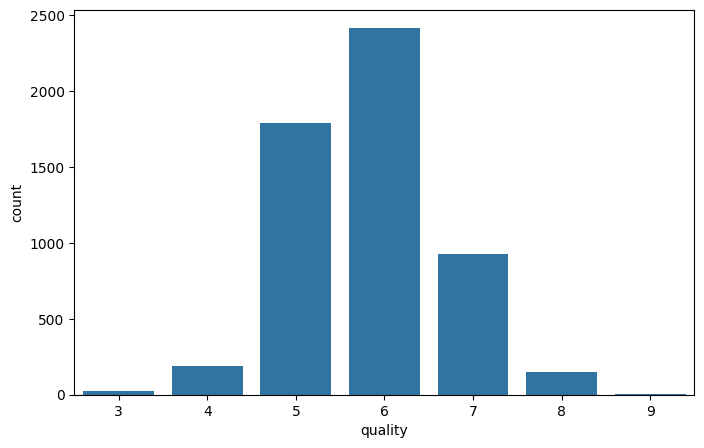

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 데이터 불러오기
train = pd.read_csv('train.csv', index_col='index')

# 막대 그래프 그리기
plt.figure(figsize=(8, 5))
sns.countplot(data=train, x='quality')
plt.show()

In [10]:
import pandas as pd

train = pd.read_csv('train.csv', index_col='index')
print(train['quality'].value_counts())

quality
6    2416
5    1788
7     924
4     186
8     152
3      26
9       5
Name: count, dtype: int64


In [21]:
import pandas as pd

train_cleaned['quality'] = train['quality'].apply(lambda x: 5 if x <= 5 else (7 if x >= 7 else 6))

In [22]:
train_cleaned['quality'].value_counts()

,count
quality,
6,2037
5,1724
7,878


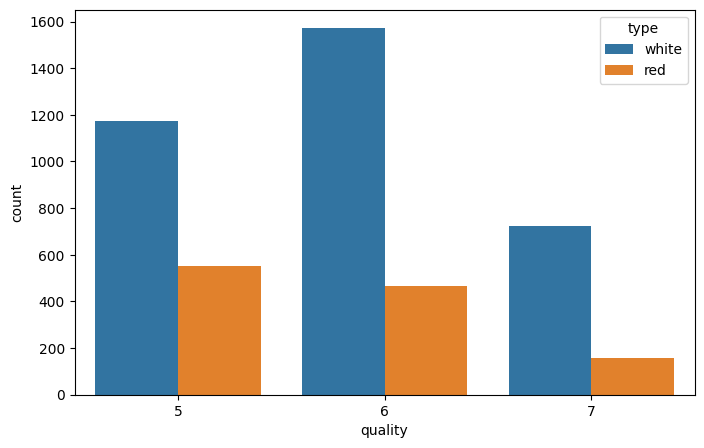

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=train_cleaned, x='quality', hue='type')
plt.show()

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

               fixed acidity   quality
fixed acidity       1.000000 -0.074783
quality            -0.074783  1.000000


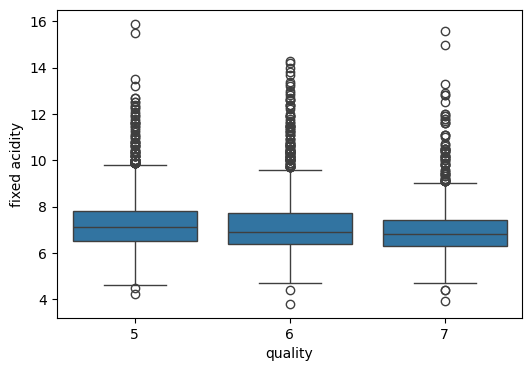

In [26]:
print(train_cleaned[['fixed acidity', 'quality']].corr())

plt.figure(figsize=(6, 4))
sns.boxplot(data=train_cleaned, x='quality', y='fixed acidity')
plt.show()

                  volatile acidity   quality
volatile acidity          1.000000 -0.249286
quality                  -0.249286  1.000000


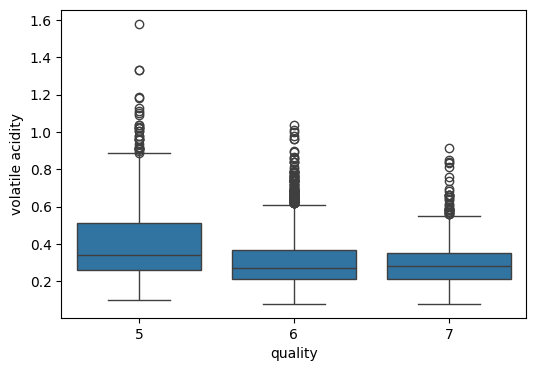

In [27]:
print(train_cleaned[['volatile acidity', 'quality']].corr())

plt.figure(figsize=(6, 4))
sns.boxplot(data=train_cleaned, x='quality', y='volatile acidity')
plt.show()

             citric acid   quality
citric acid     1.000000  0.081676
quality         0.081676  1.000000


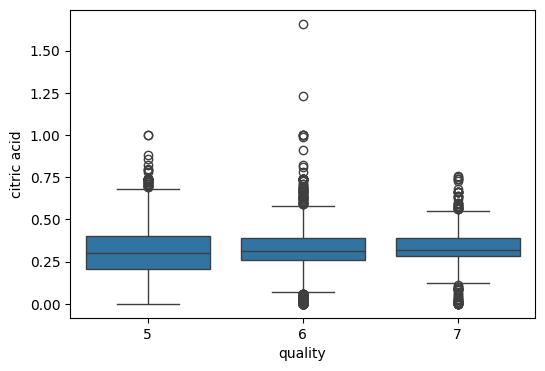

In [28]:
print(train_cleaned[['citric acid', 'quality']].corr())

plt.figure(figsize=(6, 4))
sns.boxplot(data=train_cleaned, x='quality', y='citric acid')
plt.show()

In [29]:
features = ['fixed acidity', 'volatile acidity', 'citric acid']
print(train_cleaned[features].describe())

       fixed acidity  volatile acidity  citric acid
count    4639.000000       4639.000000  4639.000000
mean        7.210013          0.342484     0.318463
std         1.301866          0.166410     0.146877
min         3.800000          0.080000     0.000000
25%         6.400000          0.230000     0.250000
50%         7.000000          0.300000     0.310000
75%         7.700000          0.410000     0.400000
max        15.900000          1.580000     1.660000


In [30]:
features = ['fixed acidity', 'volatile acidity', 'citric acid']
print(train_cleaned.groupby('quality')[features].mean())

         fixed acidity  volatile acidity  citric acid
quality                                              
5             7.333672          0.399820     0.303353
6             7.161733          0.314050     0.324197
7             7.079214          0.295871     0.334829


In [31]:
features = ['fixed acidity', 'volatile acidity', 'citric acid']

for col in features:
    Q1 = train_cleaned[col].quantile(0.25)
    Q3 = train_cleaned[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = train_cleaned[(train_cleaned[col] < lower_bound) | (train_cleaned[col] > upper_bound)]
    print(f"{col} 이상치 개수: {len(outliers)}")

fixed acidity 이상치 개수: 257
volatile acidity 이상치 개수: 238
citric acid 이상치 개수: 326


In [32]:
features = ['fixed acidity', 'volatile acidity', 'citric acid']

for col in features:
    corr = train_cleaned[col].corr(train_cleaned['quality'])
    print(f"{col}와 quality의 상관계수: {corr:.4f}")

fixed acidity와 quality의 상관계수: -0.0748
volatile acidity와 quality의 상관계수: -0.2493
citric acid와 quality의 상관계수: 0.0817


In [33]:
import numpy as np

# 0이나 음수가 있으면 로그 변환 시 에러가 나므로, 보통 np.log1p (log(1+x))를 사용합니다.
features = ['fixed acidity', 'volatile acidity', 'citric acid']

for col in features:
    # 로그 변환된 임시 컬럼 생성
    log_col = np.log1p(train_cleaned[col])

    # quality와의 상관계수 계산
    corr = log_col.corr(train_cleaned['quality'])
    print(f"로그변환된 {col}와 quality의 상관계수: {corr:.4f}")

로그변환된 fixed acidity와 quality의 상관계수: -0.0852
로그변환된 volatile acidity와 quality의 상관계수: -0.2507
로그변환된 citric acid와 quality의 상관계수: 0.0958


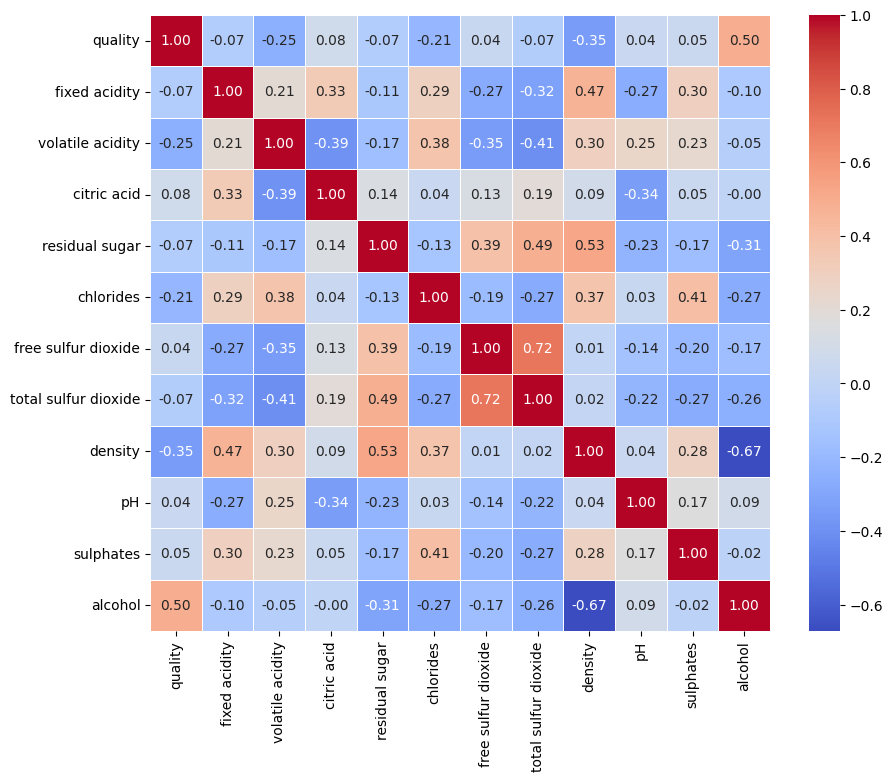

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

# 수치형 피처만 추출해서 상관관계 계산
numeric_cols = train_cleaned.select_dtypes(include=['float64', 'int64']).columns
corr_matrix = train_cleaned[numeric_cols].corr()

# 히트맵 그리기
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()